In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
etfs = ['SPY', 'TLT', 'IEF', 'GLD', 'DBC']

precios = yf.download(etfs, start='2006-03-01', auto_adjust=True)['Close']



[*********************100%***********************]  5 of 5 completed


In [3]:
print(precios)

Ticker            DBC         GLD        IEF         SPY        TLT
Date                                                               
2006-03-01  18.424036   56.099998  47.941151   88.614304  46.782764
2006-03-02  18.756998   56.740002  47.749508   88.607422  46.456997
2006-03-03  18.931408   56.279999  47.633327   88.196426  46.188152
2006-03-06  18.630156   55.230000  47.482353   87.792358  45.784832
2006-03-07  18.305120   54.950001  47.505539   87.655342  45.815884
...               ...         ...        ...         ...        ...
2026-10-08  32.910000  378.619995  89.449997  773.929993  77.870003
2026-10-09  32.959999  384.579987  89.400002  778.570007  77.980003
2026-10-12  33.330002  382.149994  89.430000  778.099976  78.050003
2026-10-13  33.480000  381.670013  89.540001  778.010010  78.370003
2026-10-14  33.305000  375.750000  89.714996  768.895020  78.885002

[5189 rows x 5 columns]


In [4]:
retornos_diarios = precios.pct_change().dropna()
print(retornos_diarios)

Ticker           DBC       GLD       IEF       SPY       TLT
Date                                                        
2006-03-02  0.018072  0.011408 -0.003997 -0.000078 -0.006963
2006-03-03  0.009298 -0.008107 -0.002433 -0.004638 -0.005787
2006-03-06 -0.015913 -0.018657 -0.003170 -0.004581 -0.008732
2006-03-07 -0.017447 -0.005070  0.000488 -0.001561  0.000678
2006-03-08 -0.016024 -0.017834  0.000489  0.002110 -0.000339
...              ...       ...       ...       ...       ...
2026-10-08  0.012304  0.007290  0.003815 -0.004233  0.009332
2026-10-09  0.001519  0.015741 -0.000559  0.005995  0.001413
2026-10-12  0.011226 -0.006319  0.000336 -0.000604  0.000898
2026-10-13  0.004500 -0.001256  0.001230 -0.000116  0.004100
2026-10-14 -0.005227 -0.015511  0.001954 -0.011716  0.006571

[5188 rows x 5 columns]


In [5]:
vol_anual = retornos_diarios.std() * (252 ** 0.5)

print(vol_anual)

Ticker
DBC    0.192883
GLD    0.184687
IEF    0.068259
SPY    0.192364
TLT    0.147753
dtype: float64


In [6]:
puntajes = 1 / vol_anual
pesos = puntajes / puntajes.sum()

print(pesos)
print(pesos.sum())

Ticker
DBC    0.139309
GLD    0.145491
IEF    0.393655
SPY    0.139685
TLT    0.181860
dtype: float64
0.9999999999999999


In [7]:
# Portafolio balanceado por riesgo
ret_balanceado = (retornos_diarios * pesos).sum(axis=1)

# Portafolio 60/40
ret_6040 = retornos_diarios['SPY'] * 0.6 + retornos_diarios['IEF'] * 0.4


print(ret_balanceado)
print(ret_6040)


Date
2006-03-02    0.001327
2006-03-03   -0.002542
2006-03-06   -0.008407
2006-03-07   -0.003071
2006-03-08   -0.004401
                ...   
2026-10-08    0.005383
2026-10-09    0.003376
2026-10-12    0.000856
2026-10-13    0.001658
2026-10-14   -0.002657
Length: 5188, dtype: float64
Date
2006-03-02   -0.001646
2006-03-03   -0.003756
2006-03-06   -0.004017
2006-03-07   -0.000741
2006-03-08    0.001462
                ...   
2026-10-08   -0.001014
2026-10-09    0.003374
2026-10-12   -0.000228
2026-10-13    0.000423
2026-10-14   -0.006248
Length: 5188, dtype: float64


In [8]:
crec_balanceado = (1 + ret_balanceado).cumprod()
crec_6040 = (1 + ret_6040).cumprod()

caida_balanceado = (crec_balanceado / crec_balanceado.cummax() - 1).min()
caida_6040 = (crec_6040 / crec_6040.cummax() - 1).min()

años = len(retornos_diarios) / 252
cagr_balanceado = crec_balanceado.iloc[-1] ** (1 / años) - 1
cagr_6040 = crec_6040.iloc[-1] ** (1 / años) - 1

vol_balanceado = ret_balanceado.std() * (252 ** 0.5)
vol_6040 = ret_6040.std() * (252 ** 0.5)

In [9]:
dd_balanceado = crec_balanceado / crec_balanceado.cummax() - 1
dd_6040 = crec_6040 / crec_6040.cummax() - 1

print(dd_balanceado.idxmin())
print(dd_6040.idxmin())

2022-10-20 00:00:00
2009-03-09 00:00:00


In [10]:
nombres = {
    'SPY': 'Acciones EEUU (SPY)',
    'TLT': 'Bonos largos (TLT)',
    'IEF': 'Bonos medios (IEF)',
    'GLD': 'Oro (GLD)',
    'DBC': 'Commodities (DBC)'
}

pesos_nombres = pesos.rename(index=nombres).sort_values(ascending=False)

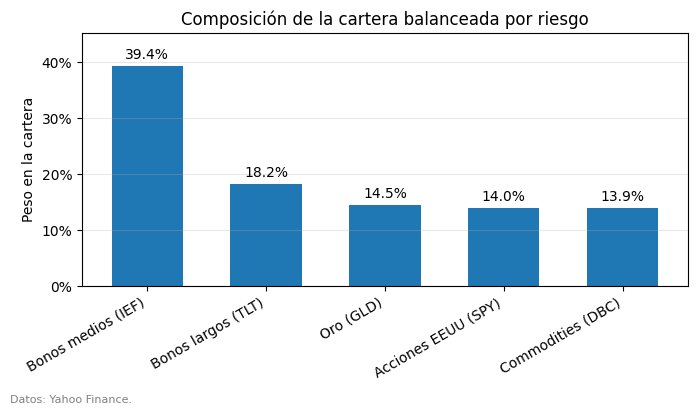

In [11]:
ax = pesos_nombres.plot(kind='bar', color='tab:blue', figsize=(7, 4), width=0.6)

ax.bar_label(ax.containers[0], labels=[f'{v:.1%}' for v in pesos_nombres], padding=3)

ax.set_ylim(0, pesos_nombres.max() * 1.15)   # deja 15% de aire arriba de la barra más alta

ax.set_title('Composición de la cartera balanceada por riesgo')
ax.set_xlabel('')
ax.set_ylabel('Peso en la cartera')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=30, ha='right')

plt.figtext(0.01, -0.02,
    'Datos: Yahoo Finance.',
    fontsize=8, color='gray')

plt.tight_layout()
plt.savefig('pesos.png', dpi=200, bbox_inches='tight')
plt.show()

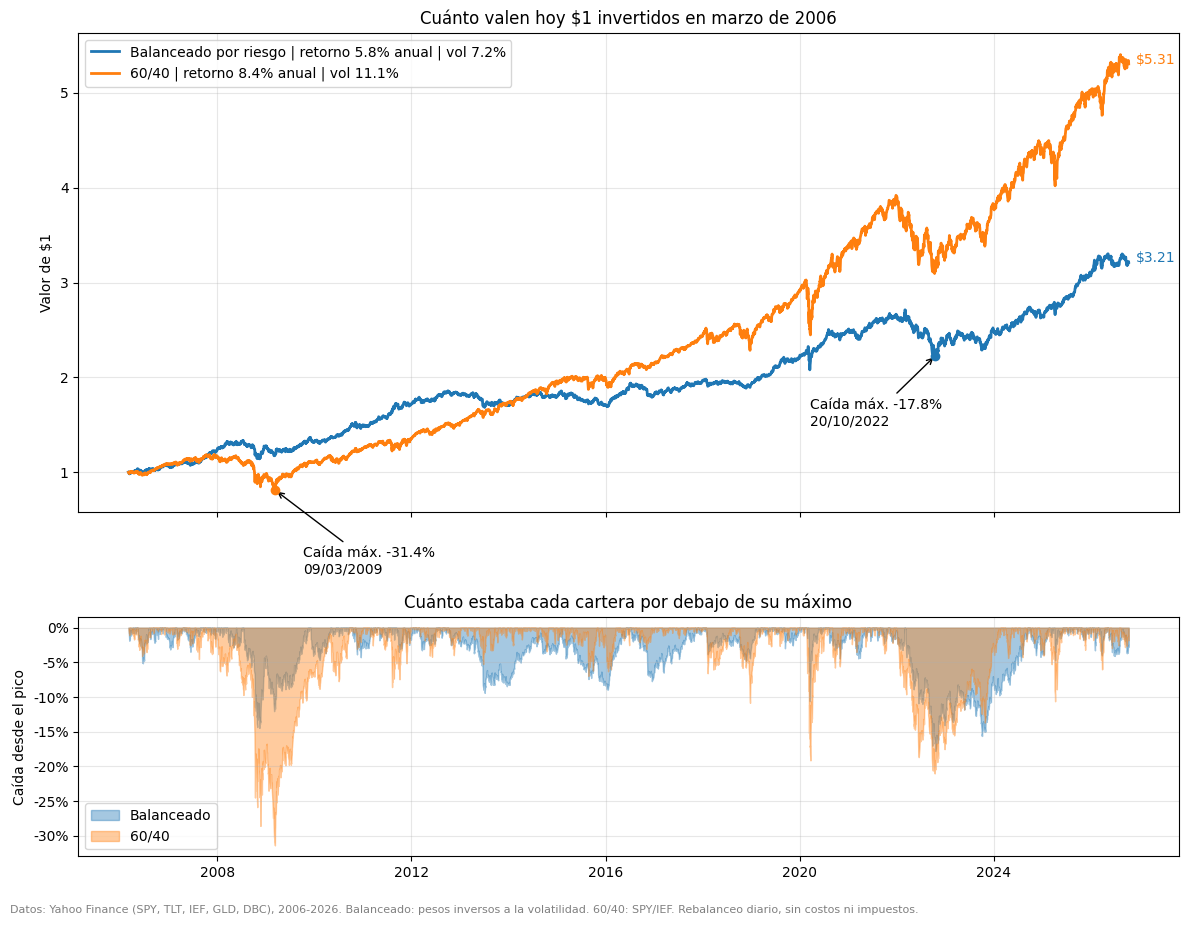

In [12]:
dd_balanceado = crec_balanceado / crec_balanceado.cummax() - 1
dd_6040 = crec_6040 / crec_6040.cummax() - 1


f_b = dd_balanceado.idxmin()
f_6 = dd_6040.idxmin()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True,
    gridspec_kw={'height_ratios': [2, 1]}
)

ax1.plot(crec_balanceado, color='tab:blue', linewidth=2,
         label=f'Balanceado por riesgo | retorno {cagr_balanceado:.1%} anual | vol {vol_balanceado:.1%}')
ax1.plot(crec_6040, color='tab:orange', linewidth=2,
         label=f'60/40 | retorno {cagr_6040:.1%} anual | vol {vol_6040:.1%}')

ax1.scatter(f_b, crec_balanceado.loc[f_b], color='tab:blue', zorder=5)
ax1.annotate(f'Caída máx. {dd_balanceado.min():.1%}\n{f_b:%d/%m/%Y}',
             (f_b, crec_balanceado.loc[f_b]),
             textcoords='offset points', xytext=(-90, -50),
             arrowprops=dict(arrowstyle='->'))

ax1.scatter(f_6, crec_6040.loc[f_6], color='tab:orange', zorder=5)
ax1.annotate(f'Caída máx. {dd_6040.min():.1%}\n{f_6:%d/%m/%Y}',
             (f_6, crec_6040.loc[f_6]),
             textcoords='offset points', xytext=(20, -60),
             arrowprops=dict(arrowstyle='->'))

ax1.annotate(f'${crec_balanceado.iloc[-1]:.2f}',
             (crec_balanceado.index[-1], crec_balanceado.iloc[-1]),
             textcoords='offset points', xytext=(5, 0), color='tab:blue')
ax1.annotate(f'${crec_6040.iloc[-1]:.2f}',
             (crec_6040.index[-1], crec_6040.iloc[-1]),
             textcoords='offset points', xytext=(5, 0), color='tab:orange')

ax1.set_title('Cuánto valen hoy $1 invertidos en marzo de 2006')
ax1.set_ylabel('Valor de $1')
ax1.legend(loc='upper left')
ax1.grid(alpha=0.3)

ax2.fill_between(dd_balanceado.index, dd_balanceado, 0, color='tab:blue', alpha=0.4, label='Balanceado')
ax2.fill_between(dd_6040.index, dd_6040, 0, color='tab:orange', alpha=0.4, label='60/40')
ax2.set_title('Cuánto estaba cada cartera por debajo de su máximo')
ax2.set_ylabel('Caída desde el pico')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax2.legend(loc='lower left')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.figtext(0.01, -0.02,
    'Datos: Yahoo Finance (SPY, TLT, IEF, GLD, DBC), 2006-2026. '
    'Balanceado: pesos inversos a la volatilidad. 60/40: SPY/IEF. '
    'Rebalanceo diario, sin costos ni impuestos.',
    fontsize=8, color='gray')
plt.savefig('grafico_carteras.png', dpi=200, bbox_inches='tight')
plt.show()

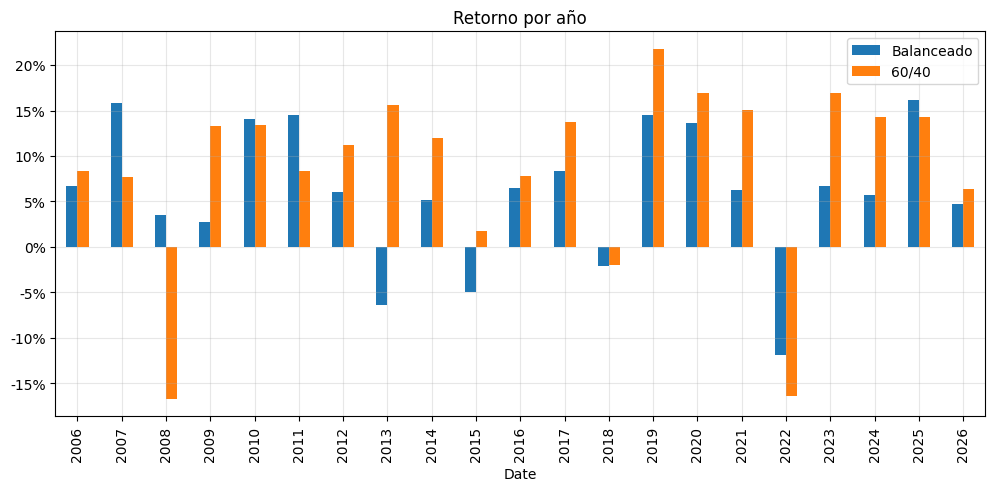

In [13]:
anual = pd.DataFrame({'Balanceado': ret_balanceado, '60/40': ret_6040})
por_año = (1 + anual).groupby(anual.index.year).prod() - 1

ax = por_año.plot(kind='bar', figsize=(12, 5), color=['tab:blue', 'tab:orange'])
ax.set_title('Retorno por año')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.grid(alpha=0.3)
plt.show()

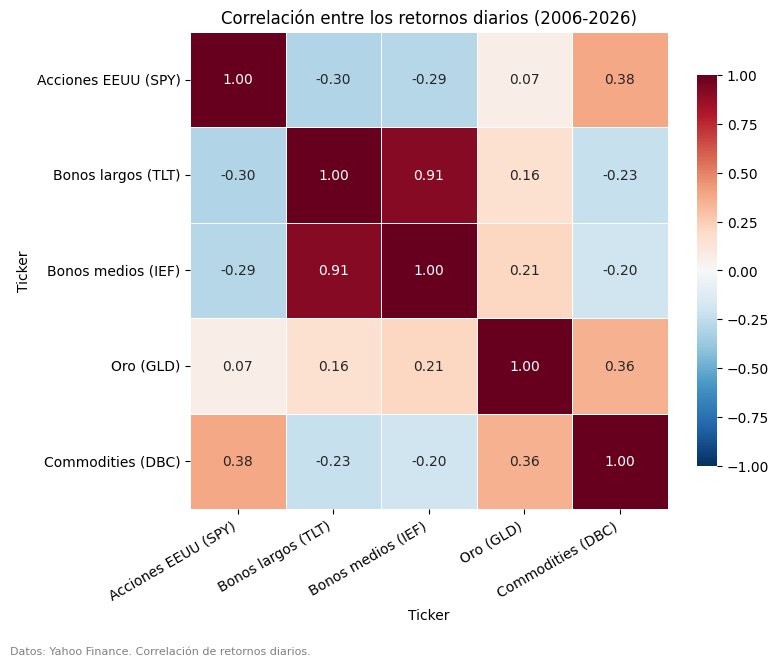

In [14]:
orden = ['SPY', 'TLT', 'IEF', 'GLD', 'DBC']
corr = retornos_diarios[orden].corr().rename(index=nombres, columns=nombres)

plt.figure(figsize=(8, 6.5))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlación entre los retornos diarios (2006-2026)')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)

plt.figtext(0.01, -0.02,
    'Datos: Yahoo Finance. Correlación de retornos diarios.',
    fontsize=8, color='gray')

plt.tight_layout()
plt.savefig('correlaciones.png', dpi=200, bbox_inches='tight')
plt.show()